# Function 5 — Week 10 full-cohort exploration

The 25 November snapshot contains 29 official observations and 28 published peer returns. 4 were added since 23 November.

[Model comparison](model_predictions.ipynb) · [Week 10 review](../../../../results/week-10-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 5
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4']
EXPECTED_ROUND_COUNTS = {0: 20, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-25"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 23 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 29
Published peer returns                28
New peer returns since 23 November     4
Total observations                    57
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                      8223.209090
Rank among official observations       6.000000
Rank in the full snapshot              6.000000
Best official score                 8662.405001
Best published peer score           6947.430895
dtype: float64

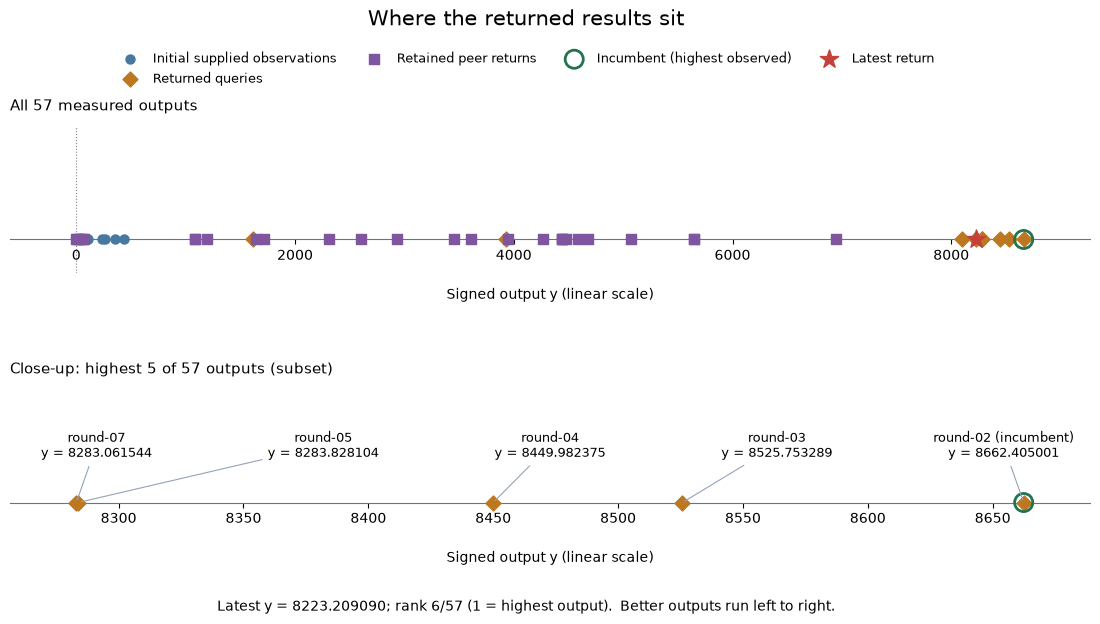

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

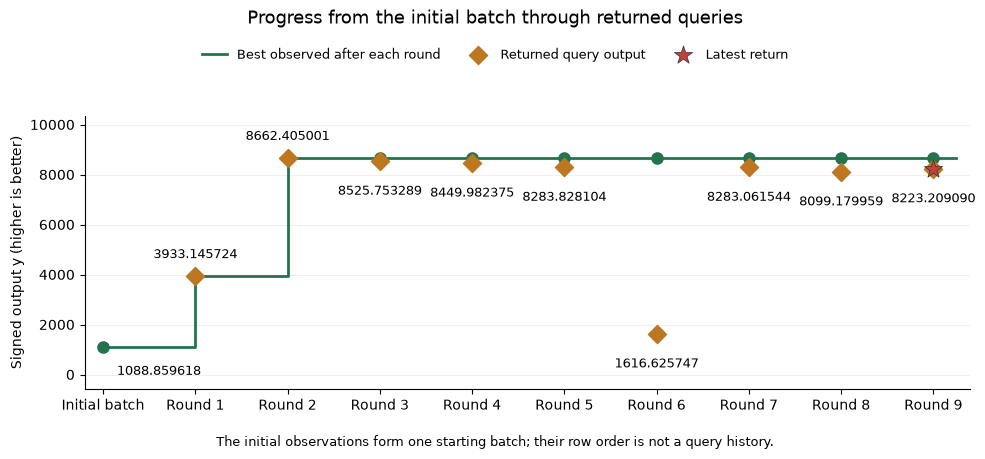

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,1088.859618,NaN
Round 1,3933.145724,3933.145724,2844.286106
Round 2,8662.405001,8662.405001,4729.259277
Round 3,8525.753289,8662.405001,-136.651712
Round 4,8449.982375,8662.405001,-212.422627
Round 5,8283.828104,8662.405001,-378.576898
Round 6,1616.625747,8662.405001,-7045.779254
Round 7,8283.061544,8662.405001,-379.343457
Round 8,8099.179959,8662.405001,-563.225042


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,x3,x4,y
21,1,round-02,0.999999,0.999999,0.999999,0.999999,8662.405001
22,2,round-03,0.996065,0.996814,0.999999,0.999999,8525.753289
23,3,round-04,0.999515,0.989282,0.999999,0.999999,8449.982375
24,4,round-05,0.999999,0.999999,0.999999,0.979636,8283.828104
26,5,round-07,0.999999,0.999999,0.979593,0.999999,8283.061544


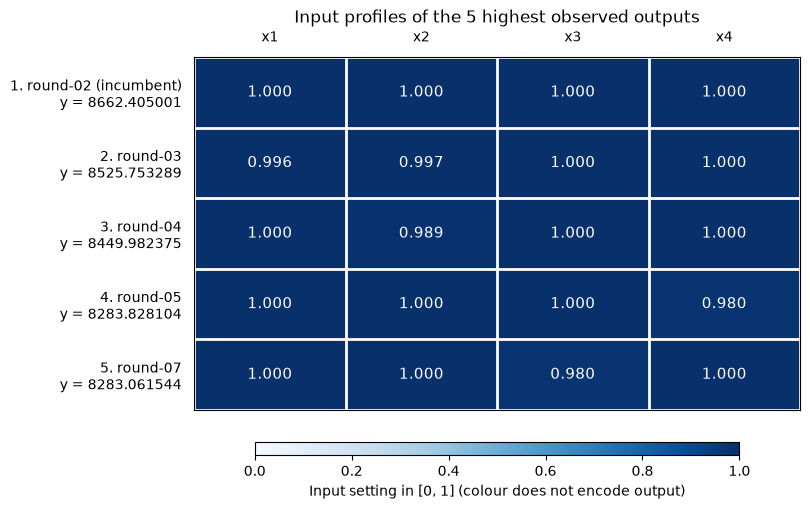

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-25",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 5,
  "intake_date": "2026-11-25",
  "official_rows": 29,
  "peer_rows": 28,
  "new_peer_rows": 4,
  "latest_output": 8223.20909004642,
  "latest_official_rank": 6,
  "latest_cohort_rank": 6,
  "official_best": 8662.405001248297,
  "peer_best": 6947.430895128993,
  "best_peer_point": [
    0.889972,
    0.999999,
    0.999999,
    0.999999
  ],
  "official_snapshot_sha256": "73cdf1d01324373ea0bebfbfb748887a6d267942125f662c57d7651ea7567693",
  "pooled_snapshot_sha256": "7ed864579eea17c8f9352134733aa130cea4852b2173f674ce506a0d5d127cf2"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

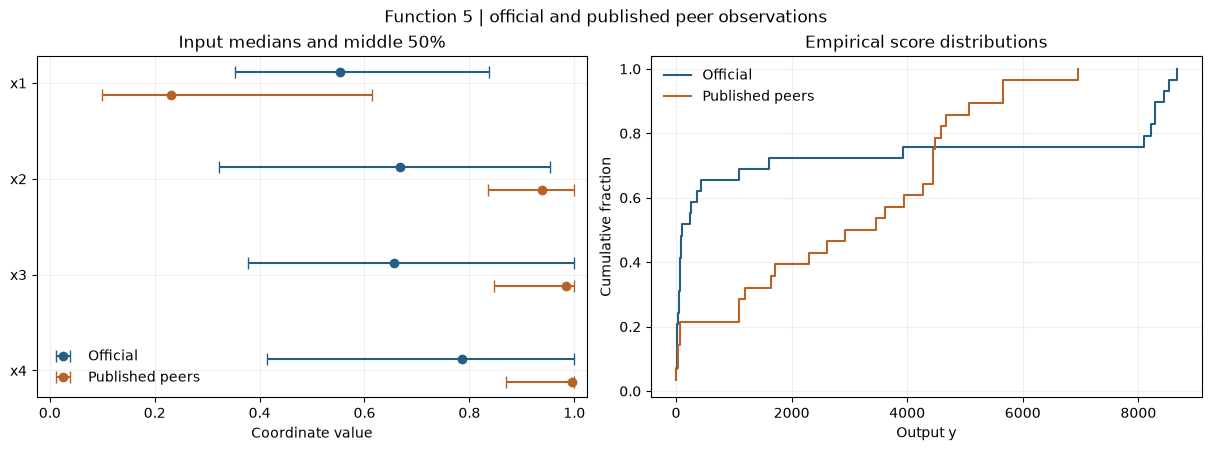

,scope,rows,rows_on_portal_boundary,score_median
0,Official,29,9,109.571876
1,Published peers,28,14,3192.295934


portal_input_groups                 56.000000
repeated_input_groups                1.000000
peer_rows_matching_official          1.000000
median_peer_to_official_distance     0.229683
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### Interpreting the diagnostics

The score and input summaries compare different collections of queried points. Peer round numbers are local to their sources. The official timeline above uses the confirmed email returns.